# Conformal Policy Selection — Replication

## Setup

In [1]:
import os, sys, warnings
for _p in ['.', 'experiments']:
    _ap = os.path.abspath(_p)
    if _ap not in sys.path:
        sys.path.insert(0, _ap)
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from experiment_utils import (
    gen_synthetic_data, score_correct, score_wrong, weights_correct, weights_wrong,
    train_ai_policy, get_ai_actions, run_selection_experiment, aggregate_results,
)

%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

SEED = 42
Q_GRID = np.arange(0.05, 1.0, 0.1)
METHODS = ('BH', 'hete')
METHOD_LABEL = {'BH': 'Weighted BH', 'hete': 'Weighted CS'}
METHOD_COLOR = {'BH': '#0072B2', 'hete': '#D55E00'}

## 1. Synthetic doubly-robust FDR control


In [2]:
N_TRAIN, N_CALIB, N_TEST, P, SIG, C = 200, 500, 100, 5, 1.0, 0.0
N_REPS_SYNTH = 400

np.random.seed(SEED)
beta_0 = np.random.normal(0, 1, P)
beta_1 = np.random.normal(0, 1, P)
beta_T = np.random.normal(0, 1, P)
beta_wrong_0 = np.random.normal(0, 1, P) * 3
beta_wrong_1 = np.random.normal(0, 1, P) * 3
beta_wrong_w = np.random.normal(0, 1, P)

SCENARIOS = ['Both correct', 'Correct W, wrong S', 'Wrong W, correct S', 'Both wrong']

def synth_rep(rep):
    np.random.seed(SEED + rep + 1)
    X_tr, _, _, Y_tr, T_tr, _ = gen_synthetic_data(N_TRAIN, P, beta_0, beta_1, beta_T, SIG)
    X_ca, _, _, Y_ca, T_ca, prob_ca = gen_synthetic_data(N_CALIB, P, beta_0, beta_1, beta_T, SIG)
    X_te, Y0_te, Y1_te, _, _, prob_te = gen_synthetic_data(N_TEST, P, beta_0, beta_1, beta_T, SIG)
    policy = train_ai_policy(X_tr, Y_tr, T_tr)
    a_ca = get_ai_actions(policy, X_ca)
    a_te = get_ai_actions(policy, X_te)
    T_te = a_te
    y_policy = Y0_te * (1 - a_te) + Y1_te * a_te
    c_te = np.full(N_TEST, C)
    s_corr_ca = score_correct(X_ca, Y_ca, T_ca, beta_0, beta_1)
    s_corr_te = c_te - (X_te @ beta_0 * (1 - a_te) + X_te @ beta_1 * a_te)
    s_wrong_ca = score_wrong(X_ca, Y_ca, T_ca, beta_wrong_0, beta_wrong_1)
    s_wrong_te = c_te - (X_te @ beta_wrong_0 * (1 - a_te) + X_te @ beta_wrong_1 * a_te)
    w_corr_ca = weights_correct(T_ca, prob_ca, a_ca)
    w_corr_te = weights_correct(T_te, prob_te, a_te)
    w_wrong_ca = weights_wrong(X_ca, T_ca, beta_wrong_w, a_ca)
    w_wrong_te = weights_wrong(X_te, T_te, beta_wrong_w, a_te)
    combos = [
        (s_corr_ca,  w_corr_ca,  s_corr_te,  w_corr_te),
        (s_wrong_ca, w_corr_ca,  s_wrong_te, w_corr_te),
        (s_corr_ca,  w_wrong_ca, s_corr_te,  w_wrong_te),
        (s_wrong_ca, w_wrong_ca, s_wrong_te, w_wrong_te),
    ]
    return combos, y_policy, c_te

synth_runs = {s: [] for s in SCENARIOS}
for rep in range(N_REPS_SYNTH):
    combos, y_policy, c_te = synth_rep(rep)
    for name, (sc, wc, st, wt) in zip(SCENARIOS, combos):
        synth_runs[name].append(
            run_selection_experiment(sc, wc, st, wt, y_policy, c_te, Q_GRID, METHODS))

synth_agg = {s: aggregate_results(synth_runs[s], Q_GRID, METHODS) for s in SCENARIOS}
print(f'done: {N_REPS_SYNTH} replications x 4 scenarios')

done: 400 replications x 4 scenarios


FDR stays under the nominal line whenever either the reward model or the propensity weights is correct, and only uncontrolled when both are wrong.

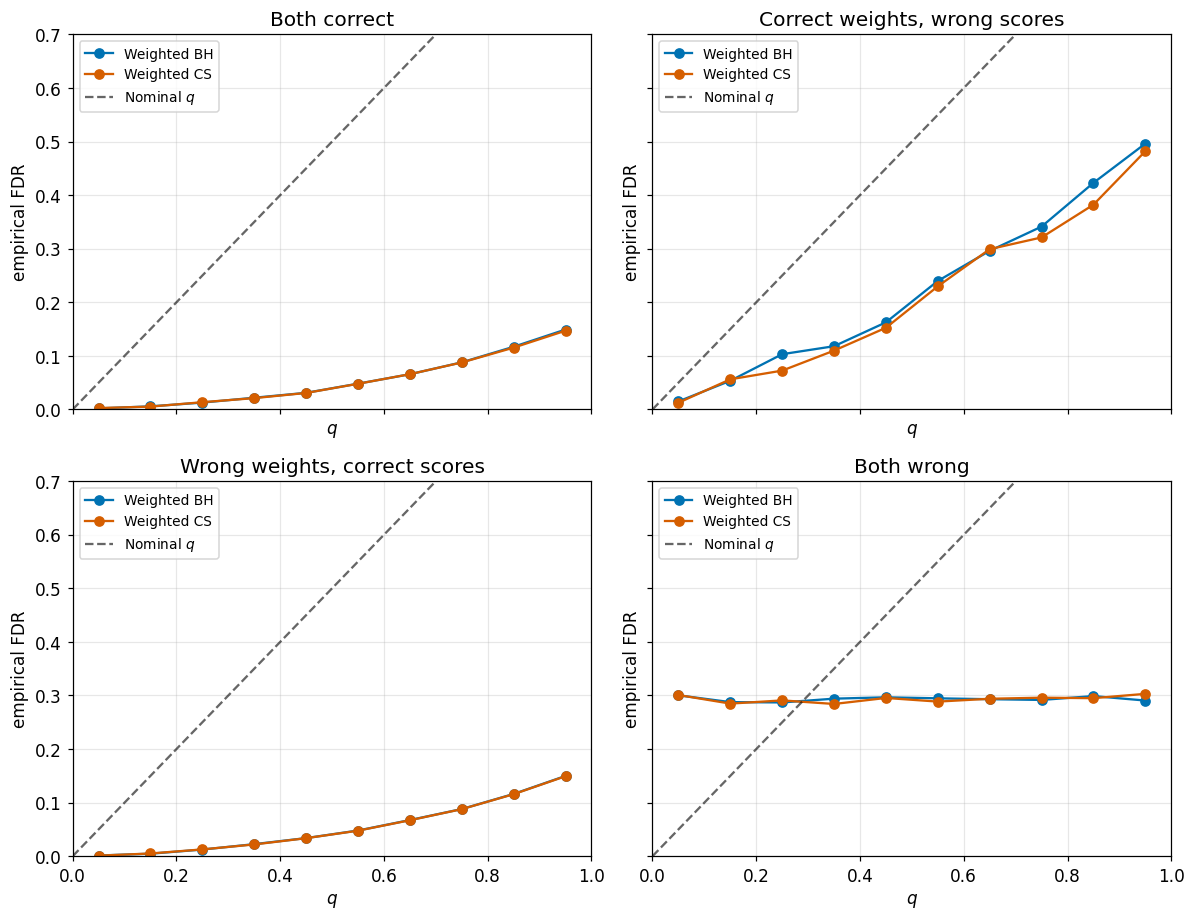

In [3]:
titles = ['Both correct', 'Correct weights, wrong scores',
          'Wrong weights, correct scores', 'Both wrong']
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True, sharey=True)
for ax, name, title in zip(axes.flat, SCENARIOS, titles):
    agg = synth_agg[name]
    for method in METHODS:
        ax.plot(Q_GRID, agg[f'fdr_{method}_mean'], marker='o', color=METHOD_COLOR[method],
                label=METHOD_LABEL[method])
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Nominal $q$')
    ax.set_title(title); ax.set_xlim(0, 1); ax.set_ylim(0, 0.7)
    ax.set_xlabel('$q$'); ax.set_ylabel('empirical FDR'); ax.grid(alpha=0.3)
    ax.legend(loc='upper left', fontsize=9)
fig.tight_layout(); plt.show()

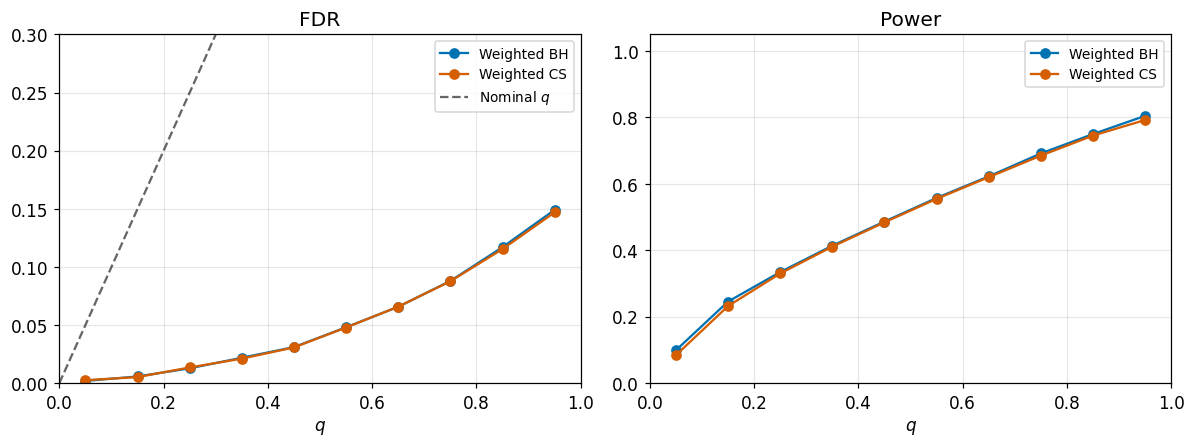

In [4]:
agg = synth_agg['Both correct']
fig, (axf, axp) = plt.subplots(1, 2, figsize=(11, 4.2))
for method in METHODS:
    axf.plot(Q_GRID, agg[f'fdr_{method}_mean'], marker='o', color=METHOD_COLOR[method],
             label=METHOD_LABEL[method])
    axp.plot(Q_GRID, agg[f'power_{method}_mean'], marker='o', color=METHOD_COLOR[method],
             label=METHOD_LABEL[method])
axf.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Nominal $q$')
axf.set_title('FDR'); axf.set_ylim(0, 0.3)
axp.set_title('Power'); axp.set_ylim(0, 1.05)
for ax in (axf, axp):
    ax.set_xlabel('$q$'); ax.set_xlim(0, 1); ax.grid(alpha=0.3); ax.legend(loc='best', fontsize=9)
fig.tight_layout(); plt.show()

In [5]:
table_runs = {s: [] for s in SCENARIOS}
for rep in range(N_REPS_SYNTH):
    combos, y_policy, c_te = synth_rep(rep)
    for name, (sc, wc, st, wt) in zip(SCENARIOS, combos):
        table_runs[name].append(
            run_selection_experiment(sc, wc, st, wt, y_policy, c_te, Q_GRID, ('BH',)))
table_agg = {s: aggregate_results(table_runs[s], Q_GRID, ('BH',)) for s in SCENARIOS}

report_q = [0.15, 0.25, 0.55, 0.95]
qi = [int(np.argmin(np.abs(Q_GRID - q))) for q in report_q]
pd.DataFrame(
    {f'q={q}': [table_agg[s]['fdr_BH_mean'][i] for s in SCENARIOS] for q, i in zip(report_q, qi)},
    index=SCENARIOS).round(3)

,q=0.15,q=0.25,q=0.55,q=0.95
Both correct,0.005,0.013,0.048,0.149
"Correct W, wrong S",0.055,0.083,0.225,0.502
"Wrong W, correct S",0.005,0.013,0.048,0.150
Both wrong,0.287,0.300,0.295,0.297


## 2. LaLonde job training



In [6]:
C_LALONDE = 4000.0
N_REPS_LALONDE = 100
df = pd.read_csv('data/lalonde_data.csv')
feat = ['age', 'educ', 'black', 'hispan', 'married', 'nodegree', 're74', 're75']
X_all = df[feat].values.astype(float)
T_all = df['treat'].values.astype(int)
Y_all = df['re78'].values.astype(float)
n_total = len(Y_all)
print(f'{n_total} individuals, {T_all.sum()} treated, {(1 - T_all).sum()} control')

lalonde_runs = []
for rep in range(N_REPS_LALONDE):
    rng = np.random.RandomState(SEED + rep)
    idx_tr, idx_rest = train_test_split(np.arange(n_total), test_size=0.7, stratify=T_all, random_state=rng)
    idx_ca, idx_te = train_test_split(idx_rest, test_size=3 / 7, stratify=T_all[idx_rest], random_state=rng)

    m0 = RandomForestRegressor(n_estimators=100, random_state=rng.randint(10**6))
    m0.fit(X_all[idx_tr][T_all[idx_tr] == 0], Y_all[idx_tr][T_all[idx_tr] == 0])
    m1 = RandomForestRegressor(n_estimators=100, random_state=rng.randint(10**6))
    m1.fit(X_all[idx_tr][T_all[idx_tr] == 1], Y_all[idx_tr][T_all[idx_tr] == 1])
    scaler = StandardScaler().fit(X_all[idx_tr])
    prop = LogisticRegression(max_iter=2000, random_state=rng.randint(10**6))
    prop.fit(scaler.transform(X_all[idx_tr]), T_all[idx_tr])

    def actions(Z):
        return (m1.predict(Z) > m0.predict(Z)).astype(int)

    def outcome(Z, t):
        return np.where(t == 1, m1.predict(Z), m0.predict(Z))

    a_ca = actions(X_all[idx_ca])
    a_te = actions(X_all[idx_te])
    calib_scores = Y_all[idx_ca] - outcome(X_all[idx_ca], T_all[idx_ca])
    mu_te = outcome(X_all[idx_te], a_te)
    test_scores = C_LALONDE - mu_te

    p_ca = prop.predict_proba(scaler.transform(X_all[idx_ca]))[:, 1].clip(0.05, 0.95)
    p_te = prop.predict_proba(scaler.transform(X_all[idx_te]))[:, 1].clip(0.05, 0.95)

    def ipw(t, p, a):
        return (t == a).astype(float) / np.where(t == 1, p, 1 - p)

    calib_w = ipw(T_all[idx_ca], p_ca, a_ca)
    test_w = ipw(T_all[idx_te], p_te, a_te)
    y_policy = np.where(T_all[idx_te] == a_te, Y_all[idx_te], mu_te)
    c_te = np.full(len(idx_te), C_LALONDE)

    lalonde_runs.append(run_selection_experiment(
        calib_scores, calib_w, test_scores, test_w, y_policy, c_te, Q_GRID, METHODS))

lalonde_agg = aggregate_results(lalonde_runs, Q_GRID, METHODS)
print(f'done: {N_REPS_LALONDE} splits')

614 individuals, 185 treated, 429 control
done: 100 splits


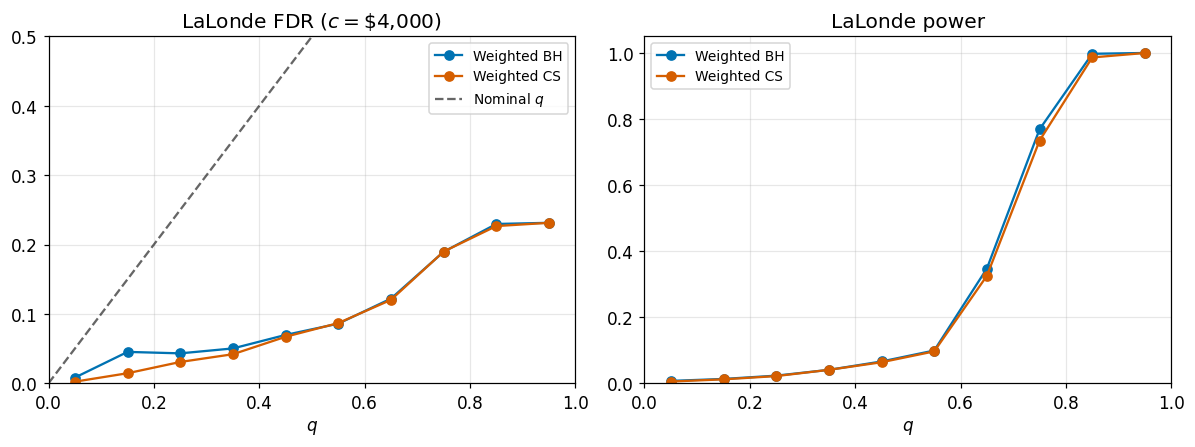

In [7]:
fig, (axf, axp) = plt.subplots(1, 2, figsize=(11, 4.2))
for method in METHODS:
    axf.plot(Q_GRID, lalonde_agg[f'fdr_{method}_mean'], marker='o', color=METHOD_COLOR[method],
             label=METHOD_LABEL[method])
    axp.plot(Q_GRID, lalonde_agg[f'power_{method}_mean'], marker='o', color=METHOD_COLOR[method],
             label=METHOD_LABEL[method])
axf.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Nominal $q$')
axf.set_title('LaLonde FDR ($c=\$4{,}000$)'); axf.set_ylim(0, 0.5)
axp.set_title('LaLonde power'); axp.set_ylim(0, 1.05)
for ax in (axf, axp):
    ax.set_xlabel('$q$'); ax.set_xlim(0, 1); ax.grid(alpha=0.3); ax.legend(loc='best', fontsize=9)
fig.tight_layout(); plt.show()

Selected trainees earn far more on average than the rest, and the two groups converge only once the budget is loose enough to select almost everyone.

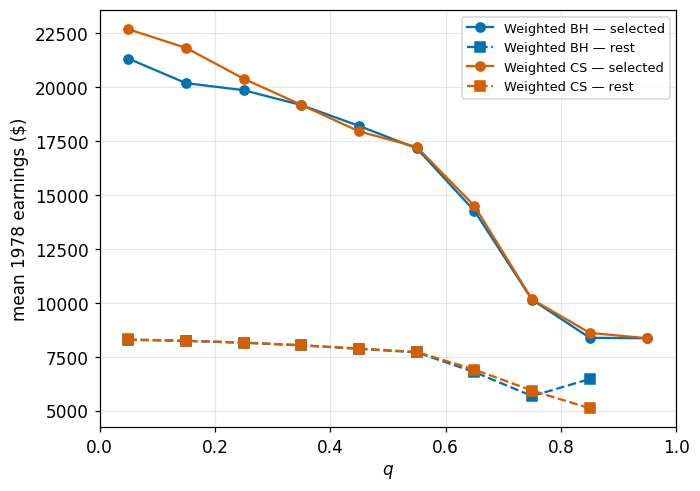

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(6.5, 4.6))
for method in METHODS:
    ax.plot(Q_GRID, lalonde_agg[f'outcome_selected_{method}_mean'], marker='o',
            color=METHOD_COLOR[method], label=f'{METHOD_LABEL[method]} — selected')
    ax.plot(Q_GRID, lalonde_agg[f'outcome_nonselected_{method}_mean'], marker='s', linestyle='--',
            color=METHOD_COLOR[method], label=f'{METHOD_LABEL[method]} — rest')
ax.set_xlabel('$q$'); ax.set_ylabel('mean 1978 earnings (\$)')
ax.set_xlim(0, 1); ax.grid(alpha=0.3); ax.legend(fontsize=8.5, loc='best')
fig.tight_layout(); plt.show()